# Detecting Dark Patterns in E-commerce Text

**Dark patterns** are interface designs that push users into decisions they did not intend: fake countdown timers ("Offer ends in 0:44:56"), pressure about stock ("Only 2 left!"), fake popularity ("23 people are viewing this"), or confusing opt-outs.

This notebook trains classifiers that decide whether a short piece of website text is a dark pattern, and analyses what they learn and where they fail.

**Approach**
1. Explore the dataset and its pattern categories.
2. Clean the text **without deleting the signals** that dark patterns rely on (numbers, prices, timers, exclamation marks).
3. Split by **website**, so the test set contains only websites the models have never seen.
4. Tune and compare classical models (TF-IDF + Logistic Regression, SVM, Random Forest, Naive Bayes).
5. Evaluate once on the test set, per pattern category, and look at the errors.
6. Optionally fine-tune BERT on the same split.

**Contents**
1. Setup and data
2. Exploratory analysis
3. Text cleaning
4. Train / test split by website
5. Does the cleaning matter?
6. Model comparison
7. Final evaluation on the test set
8. What the model learned
9. BERT (optional)
10. Conclusion

## 1. Setup and data

In [1]:
import os
import re
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from text_utils import clean_text, clean_text_simple

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning,ignore::UserWarning"
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
RUN_BERT = False          # fine-tuning BERT takes ~15-30 minutes on a CPU; set True to run section 9
IMG_DIR = Path("images"); IMG_DIR.mkdir(exist_ok=True)
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)

The dataset comes from **Yada et al. (2022), [Dark patterns in e-commerce: a dataset and its baseline evaluations](https://arxiv.org/abs/2211.06543)** ([GitHub](https://github.com/yamanalab/ec-darkpattern), Apache 2.0 license). The dark pattern texts were collected by Mathur et al. (2019) from about 11,000 shopping websites; the non-dark-pattern texts were scraped from the same websites.

| Column | Meaning |
|---|---|
| `page_id` | Website the text comes from |
| `text` | Text of the interface element |
| `label` | 1 = dark pattern, 0 = not a dark pattern |
| `Pattern Category` | Type of dark pattern |

In [2]:
df = pd.read_csv("data/dataset.tsv", sep="\t")
df = df.rename(columns={"Pattern Category": "category"})
print(f"{len(df)} texts from {df['page_id'].nunique()} websites, {df['text'].nunique()} unique texts")
df.sample(8, random_state=1)

2356 texts from 1248 websites, 2356 unique texts


,page_id,text,label,category
1204,120,Purchased 6 times this week.,1,Social Proof
50,1119,You can change your preference here Shop for ...,0,Not Dark Pattern
812,1536,Striped Tops,0,Not Dark Pattern
1197,272,Help us #savethefishies.,0,Not Dark Pattern
920,1159,Only one item left in stock!,1,Scarcity
1606,247,Please try again,0,Not Dark Pattern
540,505,Your order is reserved for 09:35 minutes!,1,Urgency
397,1059,Limited time only: FREE SHIPPING on all orders...,1,Urgency


## 2. Exploratory analysis

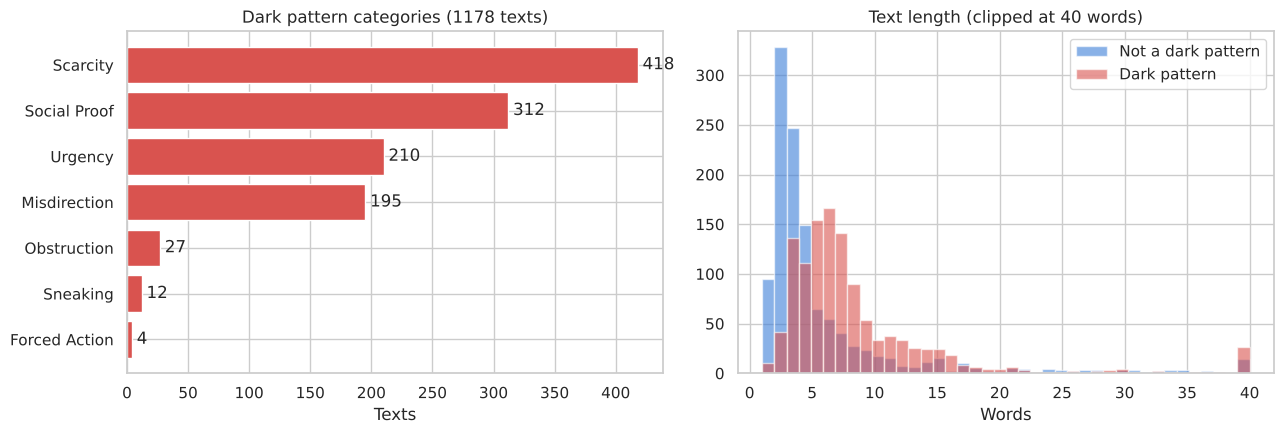

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

cats = df.loc[df.label == 1, "category"].value_counts()
axes[0].barh(cats.index[::-1], cats.values[::-1], color="#d9534f")
for i, v in enumerate(cats.values[::-1]):
    axes[0].text(v + 4, i, str(v), va="center")
axes[0].set_title(f"Dark pattern categories ({cats.sum()} texts)")
axes[0].set_xlabel("Texts")

words = df["text"].str.split().str.len()
for label, name, color in [(0, "Not a dark pattern", "#3b7dd8"), (1, "Dark pattern", "#d9534f")]:
    axes[1].hist(words[df.label == label].clip(upper=40), bins=40, alpha=0.6, label=name, color=color)
axes[1].set_title("Text length (clipped at 40 words)")
axes[1].set_xlabel("Words")
axes[1].legend()
plt.tight_layout()
plt.savefig(IMG_DIR / "categories_and_length.png", dpi=120, bbox_inches="tight")
plt.show()

* The two classes are perfectly balanced (1,178 each), but the dark pattern **categories are not**: Scarcity, Social Proof, Urgency and Misdirection make up 96% of the dark patterns. Sneaking (12) and Forced Action (4) are too rare to learn reliably.
* The texts are very short (median 3 words for normal texts, 6 for dark patterns), so every word and number counts.

## 3. Text cleaning

The first version of this project removed everything except letters and also removed English stopwords. That deletes exactly what many dark patterns consist of:

In [4]:
examples = ["Hurry! Only 2 left in stock", "0:44:56", "$132.90 $99.00", "Save 20% today!",
            "23 people are viewing this right now"]
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
pd.DataFrame({
    "original": examples,
    "first version (letters only, stopwords removed)": [
        " ".join(w for w in clean_text_simple(t).split() if w not in ENGLISH_STOP_WORDS) for t in examples],
    "new cleaning": [clean_text(t) for t in examples],
})

,original,"first version (letters only, stopwords removed)",new cleaning
0,Hurry! Only 2 left in stock,hurry left stock,hurry tok_excl only tok_num left in stock
1,0:44:56,,tok_timer
2,$132.90 $99.00,,tok_price tok_price
3,Save 20% today!,save today,save tok_percent today tok_excl
4,23 people are viewing this right now,people viewing right,tok_num people are viewing this right now


Numbers, timers and prices disappear, and "only", "left" or "now" are on the stopword list. The new `clean_text` (in `text_utils.py`) replaces them with tokens such as `tok_num`, `tok_timer`, `tok_price`, `tok_percent` and `tok_excl`, and stopwords are kept.

In [5]:
df["clean"] = df["text"].apply(clean_text)
df["clean_simple"] = df["text"].apply(clean_text_simple)
print("Texts that become empty with the first cleaning:", (df["clean_simple"] == "").sum())
print("Texts that become empty with the new cleaning:  ", (df["clean"] == "").sum())

Texts that become empty with the first cleaning: 11
Texts that become empty with the new cleaning:   6


## 4. Train / test split by website

Texts from the same website often share wording (the same product template, the same timer widget). With a random split, about half of the test websites would also appear in training. Here the split is done **by website** (`page_id`): 20% of the websites go to the test set, and the label balance is kept. The test set then measures how well the model handles websites it has never seen.

In [6]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(df, df["label"], groups=df["page_id"]))
train_df, test_df = df.iloc[train_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)
y_train, y_test = train_df["label"], test_df["label"]

print(f"Train: {len(train_df)} texts from {train_df.page_id.nunique()} websites ({y_train.mean():.1%} dark patterns)")
print(f"Test:  {len(test_df)} texts from {test_df.page_id.nunique()} websites ({y_test.mean():.1%} dark patterns)")
print("Websites in both sets:", len(set(train_df.page_id) & set(test_df.page_id)))

# Cross-validation inside the training set is also grouped by website
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
groups = train_df["page_id"]

Train: 1884 texts from 997 websites (50.0% dark patterns)
Test:  472 texts from 251 websites (50.0% dark patterns)
Websites in both sets: 0


## 5. Does the cleaning matter?

The same Logistic Regression is trained with four preprocessing variants and evaluated with 5-fold cross-validation (grouped by website) on the training set.

In [7]:
def tfidf_lr(stop_words=None):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), stop_words=stop_words, token_pattern=r"(?u)\b\w+\b")),
        ("clf", LogisticRegression(C=10, max_iter=3000)),
    ])

variants = {
    "First version: letters only, stopwords removed": ("clean_simple", "english"),
    "Letters only, stopwords kept": ("clean_simple", None),
    "New cleaning, stopwords removed": ("clean", "english"),
    "New cleaning, stopwords kept": ("clean", None),
}
rows = {}
for name, (col, sw) in variants.items():
    res = cross_validate(tfidf_lr(sw), train_df[col], y_train, cv=cv, groups=groups,
                         scoring=["accuracy", "f1", "recall", "roc_auc"])
    rows[name] = {m: res[f"test_{m}"].mean() for m in ["accuracy", "f1", "recall", "roc_auc"]}
cleaning_results = pd.DataFrame(rows).T.round(4)
cleaning_results.columns = ["Accuracy", "F1", "Recall", "ROC AUC"]
cleaning_results

,Accuracy,F1,Recall,ROC AUC
"First version: letters only, stopwords removed",0.9448,0.9440,0.9321,0.9786
"Letters only, stopwords kept",0.9427,0.9426,0.9427,0.9832
"New cleaning, stopwords removed",0.9607,0.9603,0.9522,0.9852
"New cleaning, stopwords kept",0.9607,0.9605,0.9565,0.9885


Keeping numbers, symbols and stopwords as information improves every metric. All following models use the new cleaning with stopwords kept.

## 6. Model comparison

Each model is a pipeline of TF-IDF features and a classifier. Hyperparameters are tuned with `GridSearchCV` (F1, 5-fold CV grouped by website) on the training set only.

Compared with the first version, **Gaussian** Naive Bayes is replaced by **Multinomial** Naive Bayes, the variant designed for word counts and TF-IDF features.

In [8]:
def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), token_pattern=r"(?u)\b\w+\b", sublinear_tf=True)

searches = {
    "Logistic Regression": (LogisticRegression(max_iter=5000),
                            {"clf__C": [1, 3, 10, 30, 100]}),
    "SVM (RBF kernel)": (SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
                         {"clf__C": [1, 10, 100], "clf__gamma": ["scale", 0.1, 1]}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
                      {"clf__max_depth": [None, 50], "clf__min_samples_leaf": [1, 2]}),
    "Multinomial Naive Bayes": (MultinomialNB(), {"clf__alpha": [0.03, 0.1, 0.3, 1.0]}),
}

best_models, cv_rows = {}, {}
for name, (clf, grid) in searches.items():
    search = GridSearchCV(Pipeline([("tfidf", tfidf()), ("clf", clf)]), grid, scoring="f1",
                          cv=cv, n_jobs=-1)
    search.fit(train_df["clean"], y_train, groups=groups)
    best_models[name] = search.best_estimator_
    cv_std = search.cv_results_["std_test_score"][search.best_index_]
    cv_rows[name] = {"CV F1": search.best_score_, "CV std": cv_std,
                     "best parameters": ", ".join(f"{k.split('__')[1]}={v}" for k, v in search.best_params_.items())}
    print(f"{name:25s} CV F1 = {search.best_score_:.4f} ± {cv_std:.4f}   {search.best_params_}")

Logistic Regression       CV F1 = 0.9646 ± 0.0097   {'clf__C': 3}


SVM (RBF kernel)          CV F1 = 0.9661 ± 0.0092   {'clf__C': 10, 'clf__gamma': 'scale'}


Random Forest             CV F1 = 0.9603 ± 0.0178   {'clf__max_depth': None, 'clf__min_samples_leaf': 1}


Multinomial Naive Bayes   CV F1 = 0.8874 ± 0.0367   {'clf__alpha': 0.3}


## 7. Final evaluation on the test set

All tuned models are evaluated once on the test websites.

In [9]:
test_rows = {}
for name, model in best_models.items():
    pred = model.predict(test_df["clean"])
    proba = model.predict_proba(test_df["clean"])[:, 1]
    test_rows[name] = {"Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                       "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                       "ROC AUC": roc_auc_score(y_test, proba)}
test_results = pd.DataFrame(test_rows).T.sort_values("F1", ascending=False).round(4)
test_results.insert(0, "CV F1", pd.Series({k: v["CV F1"] for k, v in cv_rows.items()}).round(4))
test_results

,CV F1,Accuracy,Precision,Recall,F1,ROC AUC
Logistic Regression,0.9646,0.9725,0.9665,0.9788,0.9726,0.9946
SVM (RBF kernel),0.9661,0.9703,0.9664,0.9746,0.9705,0.9946
Random Forest,0.9603,0.9682,0.9702,0.9661,0.9682,0.9967
Multinomial Naive Bayes,0.8874,0.9216,0.8755,0.9831,0.9261,0.9893


Best CV F1: SVM (RBF kernel) (0.9661); simplest model within one std: Logistic Regression
Final model: Logistic Regression

                  precision    recall  f1-score   support

Not dark pattern      0.979     0.966     0.972       236
    Dark pattern      0.967     0.979     0.973       236

        accuracy                          0.972       472
       macro avg      0.973     0.972     0.972       472
    weighted avg      0.973     0.972     0.972       472



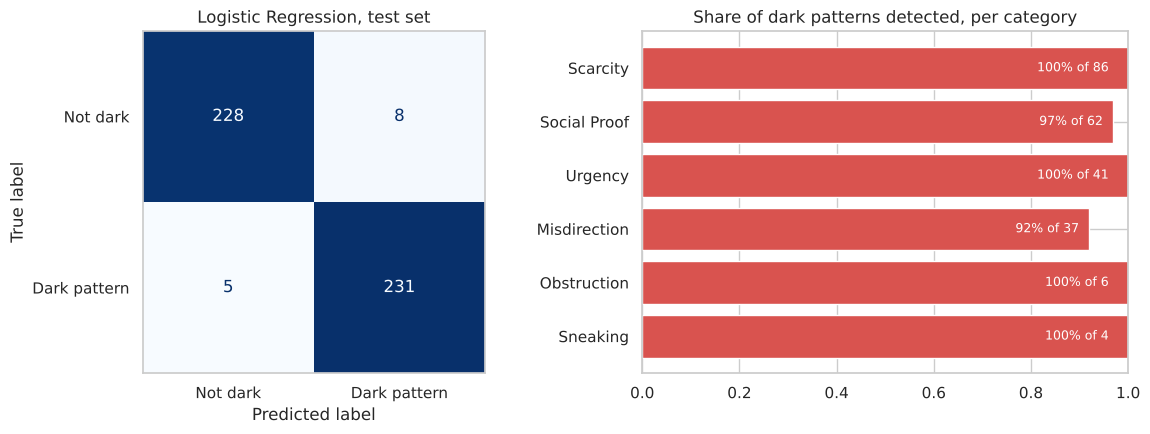

,texts,detected,recall
category,,,
Scarcity,86,86,1.000
Social Proof,62,60,0.968
Urgency,41,41,1.000
Misdirection,37,34,0.919
Obstruction,6,6,1.000
Sneaking,4,4,1.000


In [10]:
# Model choice uses cross-validation only. If several models are within one standard deviation
# of the best CV score, the simplest one is preferred (order below), because the difference is noise.
SIMPLICITY = ["Logistic Regression", "Multinomial Naive Bayes", "SVM (RBF kernel)", "Random Forest"]
top = max(cv_rows, key=lambda k: cv_rows[k]["CV F1"])
cutoff = cv_rows[top]["CV F1"] - cv_rows[top]["CV std"]
best_name = next(m for m in SIMPLICITY if cv_rows[m]["CV F1"] >= cutoff)
final_model = best_models[best_name]
print(f"Best CV F1: {top} ({cv_rows[top]['CV F1']:.4f}); simplest model within one std: {best_name}")
test_df["pred"] = final_model.predict(test_df["clean"])
test_df["proba"] = final_model.predict_proba(test_df["clean"])[:, 1]
print(f"Final model: {best_name}\n")
print(classification_report(y_test, test_df["pred"], target_names=["Not dark pattern", "Dark pattern"], digits=3))

# Recall per dark pattern category: which kinds of dark patterns does the model miss?
per_cat = (test_df[test_df.label == 1].groupby("category")
           .agg(texts=("pred", "size"), detected=("pred", "sum")))
per_cat["recall"] = (per_cat["detected"] / per_cat["texts"]).round(3)
per_cat = per_cat.sort_values("texts", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, test_df["pred"], display_labels=["Not dark", "Dark pattern"],
                                        cmap="Blues", values_format="d", colorbar=False, ax=axes[0])
axes[0].grid(False)
axes[0].set_title(f"{best_name}, test set")
axes[1].barh(per_cat.index[::-1], per_cat["recall"][::-1], color="#d9534f")
for i, (r, n) in enumerate(zip(per_cat["recall"][::-1], per_cat["texts"][::-1])):
    axes[1].text(min(r, 0.98) - 0.02, i, f"{r:.0%} of {n}", va="center", ha="right", color="white", fontsize=9)
axes[1].set_xlim(0, 1)
axes[1].set_title("Share of dark patterns detected, per category")
plt.tight_layout()
plt.savefig(IMG_DIR / "test_results.png", dpi=120, bbox_inches="tight")
plt.show()
per_cat

### Errors

In [11]:
pd.set_option("display.max_colwidth", 90)
errors = test_df[test_df["pred"] != test_df["label"]].copy()
errors["error"] = np.where(errors["label"] == 1, "missed dark pattern", "false alarm")
print(f"{len(errors)} errors out of {len(test_df)} test texts")
errors.sort_values("proba")[["error", "category", "text", "proba"]].round(3).head(25)

13 errors out of 472 test texts


,error,category,text,proba
216,missed dark pattern,Misdirection,Let's make sure you have everything else you need,0.211
202,missed dark pattern,Social Proof,MOST POPULAR,0.226
453,missed dark pattern,Misdirection,Yes! Upgrade my purchase,0.322
461,missed dark pattern,Social Proof,What people are saying about us...,0.337
219,missed dark pattern,Misdirection,"""Your purchase entitles you to the following special""",0.339
93,false alarm,Not Dark Pattern,Subscribe! Don’t be caught empty handed,0.560
150,false alarm,Not Dark Pattern,"Plus, get free shipping on your first order!",0.569
439,false alarm,Not Dark Pattern,Out of Stock!,0.588
161,false alarm,Not Dark Pattern,A very fun outfit for a less formal event like a sangeet! Husband said the bell bottom...,0.651
137,false alarm,Not Dark Pattern,I absolutely loved it! It made everyone laugh and my desk gets an obscene amount of co...,0.658


## 8. What the model learned

For a linear model, each word or token has a weight. The largest positive weights push a text towards "dark pattern", the largest negative weights towards "not a dark pattern".

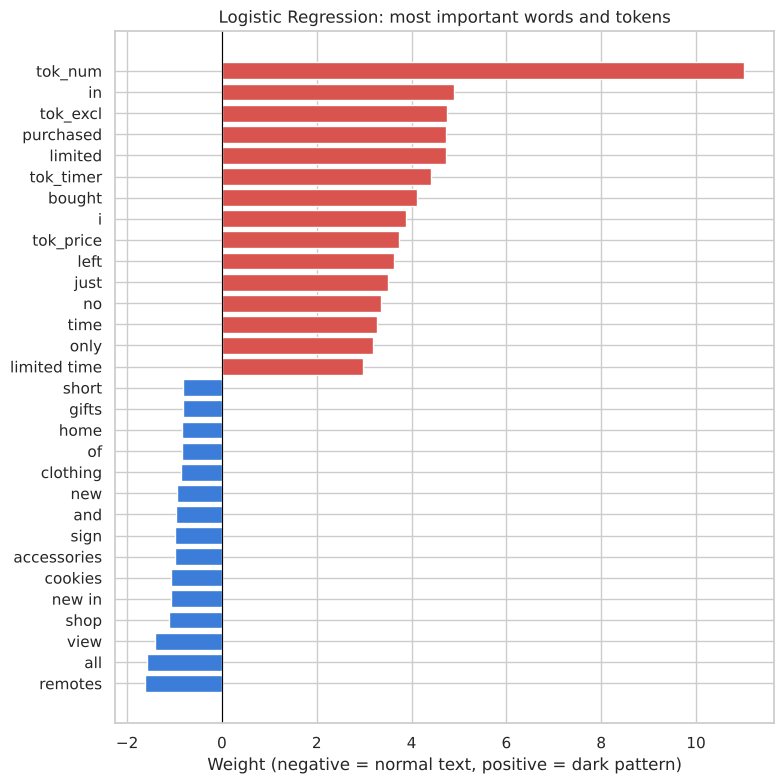

In [12]:
lr_model = best_models["Logistic Regression"]
vocab = lr_model.named_steps["tfidf"].get_feature_names_out()
coef = lr_model.named_steps["clf"].coef_[0]
order = np.argsort(coef)
n = 15
top = np.r_[order[:n], order[-n:]]

plt.figure(figsize=(8, 8))
plt.barh(vocab[top], coef[top], color=["#3b7dd8"] * n + ["#d9534f"] * n)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression: most important words and tokens")
plt.xlabel("Weight (negative = normal text, positive = dark pattern)")
plt.tight_layout()
plt.savefig(IMG_DIR / "top_features.png", dpi=120, bbox_inches="tight")
plt.show()

In [13]:
# Save the Logistic Regression pipeline for app.py: fast, small and explainable
joblib.dump(lr_model, MODEL_DIR / "dark_pattern_lr.joblib")
print("Saved", MODEL_DIR / "dark_pattern_lr.joblib")

Saved models/dark_pattern_lr.joblib


## 9. BERT (optional)

Fine-tunes `bert-base-uncased` on exactly the same train/test split. BERT gets the **original text**, because its tokenizer handles numbers and punctuation itself.

This takes about 15–30 minutes on a CPU, so it only runs when `RUN_BERT = True` (cell 1). The training loop is written directly in PyTorch, which works with both transformers v4 and v5.

In [14]:
if RUN_BERT:
    import torch
    from torch.utils.data import DataLoader, TensorDataset
    from transformers import AutoModelForSequenceClassification, AutoTokenizer, logging as hf_logging

    hf_logging.set_verbosity_error()
    os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
    torch.manual_seed(RANDOM_STATE)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    BERT_NAME, MAX_LEN, EPOCHS, BATCH, LR = "bert-base-uncased", 64, 3, 16, 2e-5
    tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)
    bert = AutoModelForSequenceClassification.from_pretrained(BERT_NAME, num_labels=2).to(device)

    def encode(texts, labels):
        enc = tokenizer(list(texts), padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt")
        return TensorDataset(enc["input_ids"], enc["attention_mask"], torch.tensor(labels.values))

    train_loader = DataLoader(encode(train_df["text"], y_train), batch_size=BATCH, shuffle=True)
    test_loader = DataLoader(encode(test_df["text"], y_test), batch_size=64)

    optimizer = torch.optim.AdamW(bert.parameters(), lr=LR)
    total_steps = len(train_loader) * EPOCHS
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: max(0.0, 1 - step / total_steps))

    for epoch in range(EPOCHS):
        bert.train()
        total = 0.0
        for ids, mask, labels in train_loader:
            optimizer.zero_grad()
            out = bert(input_ids=ids.to(device), attention_mask=mask.to(device), labels=labels.to(device))
            out.loss.backward()
            optimizer.step()
            scheduler.step()
            total += out.loss.item()
        print(f"Epoch {epoch + 1}/{EPOCHS}  loss {total / len(train_loader):.4f}")

    bert.eval()
    probs = []
    with torch.no_grad():
        for ids, mask, _ in test_loader:
            logits = bert(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
            probs.extend(logits.softmax(dim=-1)[:, 1].cpu().numpy())
    probs = np.array(probs)
    bert_pred = (probs >= 0.5).astype(int)

    test_results.loc["BERT (bert-base-uncased)"] = {
        "CV F1": np.nan, "Accuracy": accuracy_score(y_test, bert_pred),
        "Precision": precision_score(y_test, bert_pred), "Recall": recall_score(y_test, bert_pred),
        "F1": f1_score(y_test, bert_pred), "ROC AUC": roc_auc_score(y_test, probs)}
    print(classification_report(y_test, bert_pred, target_names=["Not dark pattern", "Dark pattern"], digits=3))
    display(test_results.sort_values("F1", ascending=False).round(4))
else:
    print("Skipped. Set RUN_BERT = True in the first code cell to fine-tune BERT.")

Skipped. Set RUN_BERT = True in the first code cell to fine-tune BERT.


## 10. Conclusion

* **Preprocessing mattered more than the choice of model.** Removing numbers, symbols and stopwords deleted the signals dark patterns are built from ("Only **2** left**!**", countdown timers, prices). Keeping them as tokens raised the cross-validated F1 of the same Logistic Regression from 94.4% to 96.1%, and Logistic Regression, SVM and Random Forest then score within about one point of each other.
* **A simple linear model is very strong** on this task. TF-IDF with Logistic Regression is fast, small, and its decisions can be read directly from the word weights.
* **The test set contains only unseen websites**, so the scores estimate performance on new shops rather than on new texts from known shops.
* **The model leans heavily on numbers.** The number token `tok_num` has by far the largest weight, so harmless texts with numbers can be flagged (for example "Free returns within 30 days" gets 76%). Several false alarms in the test set are enthusiastic customer reviews with exclamation marks. Both show that the model learns surface signals typical of dark patterns, not the manipulation itself.
* **Rare categories are the weak spot.** Sneaking and Forced Action have only a handful of examples, and some patterns (e.g. Misdirection or Obstruction) are hard to recognise from a short text alone because they depend on the visual design.

**Limitations:** the texts come from English-language shopping websites collected in 2019. Many dark patterns are visual (button colours, pre-ticked boxes, hidden links) and cannot be detected from text.

## 11. Try it: Dark Pattern Detector app

The trained model can be tested in a small web app (`app.py`) with two tabs:

* **Text:** paste the text of a button, banner or product notice. The app shows the probability of a dark pattern and the words that influenced the decision.
* **Screenshot:** upload an image of a web page. The app reads the text with Tesseract OCR and checks every line.

Run the cell below (it needs `pip install gradio`). The app opens inside the notebook and at a local address such as http://127.0.0.1:7860. You can also start it from a terminal with `python app.py`.

In [ ]:
from app import build_app

demo = build_app()
demo.launch()          # use demo.launch(share=True) to get a temporary public link